# Experiment 8: Part-of-Speech Tagging using a Hidden Markov Model
**Mini-project:** Resume Analyzer Using Natural Language Processing (Group 28)

**Objective:** Implement a bigram HMM POS tagger with Viterbi decoding, evaluate it on held-out tagged text and apply it to resume sentences.

Open in Colab: [Exp8_HMM_POS_Tagging.ipynb](https://colab.research.google.com/github/GnsShubham06/resume-analyzer-nlp/blob/main/notebooks/experiments/Exp8_HMM_POS_Tagging.ipynb) &nbsp;|&nbsp; Run with **Runtime → Run all**.
Data: 100 resumes (20 per domain); the screenshots in the report use five fictional (synthetic) resumes.

In [1]:
# ---- Setup: runs in Google Colab and locally --------------------------------
# In Colab this cell downloads the project repository (code + anonymised
# dataset) from GitHub and installs the packages Colab does not ship with.
import os, sys, subprocess, warnings
warnings.filterwarnings("ignore")
REPO = "https://github.com/GnsShubham06/resume-analyzer-nlp"
if "google.colab" in sys.modules:
    if not os.path.isdir("/content/resume-analyzer-nlp"):
        subprocess.run(["git", "clone", "-q", "--depth", "1", REPO, "/content/resume-analyzer-nlp"], check=True)
    os.chdir("/content/resume-analyzer-nlp")
    extra = []
    if extra:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", *extra], check=True)
else:  # local run from notebooks/experiments/
    for _ in range(3):
        if os.path.isfile("requirements.txt"):
            break
        os.chdir("..")
sys.path.insert(0, os.getcwd())

import nltk
for pkg in ['punkt', 'punkt_tab', 'stopwords', 'wordnet', 'omw-1.4', 'averaged_perceptron_tagger', 'averaged_perceptron_tagger_eng', 'treebank', 'universal_tagset']:
    nltk.download(pkg, quiet=True)

%config InlineBackend.figure_format = "retina"
import pandas as pd
pd.set_option("display.max_colwidth", 120)
df = pd.read_csv("data/resume_dataset.csv")
df["extracted_text"] = df["extracted_text"].fillna("")
print("Project folder:", os.path.basename(os.getcwd()), "| resumes:", len(df))

Project folder: resume-analyzer-nlp | resumes: 100


In [2]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"font.size": 9, "axes.titlesize": 10})
ORDER = ["Engineering", "HR", "Finance", "Healthcare", "Agriculture"]
SAMPLE_IDS = {"Engineering": "ENG_06", "HR": "HR_06", "Finance": "FIN_07",
              "Healthcare": "HLT_04", "Agriculture": "AGR_02"}     # five fictional resumes
splits = pd.read_csv("data/processed/splits.csv")[["resume_id", "split"]]
df = df.merge(splits, on="resume_id")

import math, re
from collections import Counter, defaultdict
from nltk.corpus import treebank
sents = [[(w, t) for w, t in s if t != "X"] for s in treebank.tagged_sents(tagset="universal")]
sents = [s for s in sents if s]
cut = int(0.9 * len(sents))
train_s, test_s = sents[:cut], sents[cut:]
print(f"Penn Treebank sample (WSJ), universal tagset: {len(train_s)} training / {len(test_s)} test sentences, "
      f"{sum(map(len, train_s)):,} / {sum(map(len, test_s)):,} tokens")

Penn Treebank sample (WSJ), universal tagset: 3522 training / 392 test sentences, 84,891 / 9,172 tokens


## a. Our HMM tagger: counts → probabilities → Viterbi
P(tags, words) = Π P(tᵢ | tᵢ₋₁) · P(wᵢ | tᵢ), add-k smoothing, unknown words mapped to suffix classes.

In [3]:
def unk_class(word):
    if re.fullmatch(r"[\d.,/:-]+", word): return "<NUM>"
    for suf, cls in (("ing", "<ING>"), ("ed", "<ED>"), ("ly", "<LY>"), ("tion", "<TION>"), ("ment", "<MENT>"),
                     ("s", "<S>"), ("er", "<ER>"), ("al", "<AL>"), ("ive", "<IVE>")):
        if word.lower().endswith(suf): return cls
    return "<CAP>" if word[:1].isupper() else "<UNK>"

class HMMTagger:
    def __init__(self, k=0.01):
        self.k = k
    def norm(self, w):
        return w.lower() if w.lower() in self.vocab else unk_class(w)
    def fit(self, tagged):
        wc = Counter(w.lower() for s in tagged for w, _ in s)
        self.vocab = {w for w, c in wc.items() if c > 1}            # rare words -> unknown-word classes
        self.tags = sorted({t for s in tagged for _, t in s}); T = len(self.tags)
        self.ti = {t: i for i, t in enumerate(self.tags)}
        trans = np.zeros((T + 1, T)); emit = defaultdict(lambda: np.zeros(T))   # last row = <START>
        for s in tagged:
            prev = T
            for w, t in s:
                trans[prev, self.ti[t]] += 1; emit[self.norm(w)][self.ti[t]] += 1; prev = self.ti[t]
        self.log_trans = np.log((trans + self.k) / (trans + self.k).sum(1, keepdims=True))
        tot = sum(emit.values()); V = len(emit)
        self.log_emit = {w: np.log((c + self.k) / (tot + self.k * V)) for w, c in emit.items()}
        self.log_unseen = np.log(self.k / (tot + self.k * V))
        return self
    def viterbi(self, words):
        T, n = len(self.tags), len(words)
        V = np.full((n, T), -math.inf); B = np.zeros((n, T), dtype=int)
        e = lambda w: self.log_emit.get(self.norm(w), self.log_unseen)
        V[0] = self.log_trans[T] + e(words[0])
        for i in range(1, n):
            scores = V[i - 1][:, None] + self.log_trans[:T]           # previous tag x current tag
            B[i] = scores.argmax(0); V[i] = scores.max(0) + e(words[i])
        path = [int(V[-1].argmax())]
        for i in range(n - 1, 0, -1):
            path.append(int(B[i, path[-1]]))
        return [self.tags[j] for j in reversed(path)]
    def tag(self, words):
        return list(zip(words, self.viterbi(words)))
    def accuracy(self, tagged):
        pairs = [(p, t) for s in tagged for p, (_, t) in zip(self.viterbi([w for w, _ in s]), s)]
        return sum(p == t for p, t in pairs) / len(pairs)

hmm = HMMTagger().fit(train_s)
print("tags:", hmm.tags)

tags: ['.', 'ADJ', 'ADP', 'ADV', 'CONJ', 'DET', 'NOUN', 'NUM', 'PRON', 'PRT', 'VERB']


In [4]:
import time
t0 = time.time(); acc_own = hmm.accuracy(test_s); t_own = time.time() - t0
nltk_hmm = nltk.tag.hmm.HiddenMarkovModelTrainer().train_supervised(
    train_s, estimator=lambda fd, bins: nltk.probability.LidstoneProbDist(fd, 0.1, bins))
acc_nltk = nltk_hmm.accuracy(test_s)
wt = defaultdict(Counter)
for s in train_s:
    for w, t in s: wt[w.lower()][t] += 1
most_common = Counter(t for s in train_s for _, t in s).most_common(1)[0][0]
pairs = [((wt[w.lower()].most_common(1)[0][0] if w.lower() in wt else most_common), t) for s in test_s for w, t in s]
acc_mft = sum(p == t for p, t in pairs) / len(pairs)
display(pd.DataFrame([("Most-frequent-tag baseline", acc_mft), ("NLTK HMM tagger (Lidstone 0.1)", acc_nltk),
                      ("Our HMM + Viterbi (add-k, suffix classes)", acc_own)],
                     columns=["tagger (same training data)", "accuracy on held-out treebank"]).round(4))
print(f"Viterbi decoding of {len(test_s)} test sentences took {t_own:.1f} s")

,tagger (same training data),accuracy on held-out treebank
0,Most-frequent-tag baseline,0.9285
1,NLTK HMM tagger (Lidstone 0.1),0.9067
2,"Our HMM + Viterbi (add-k, suffix classes)",0.9453


Viterbi decoding of 392 test sentences took 0.3 s


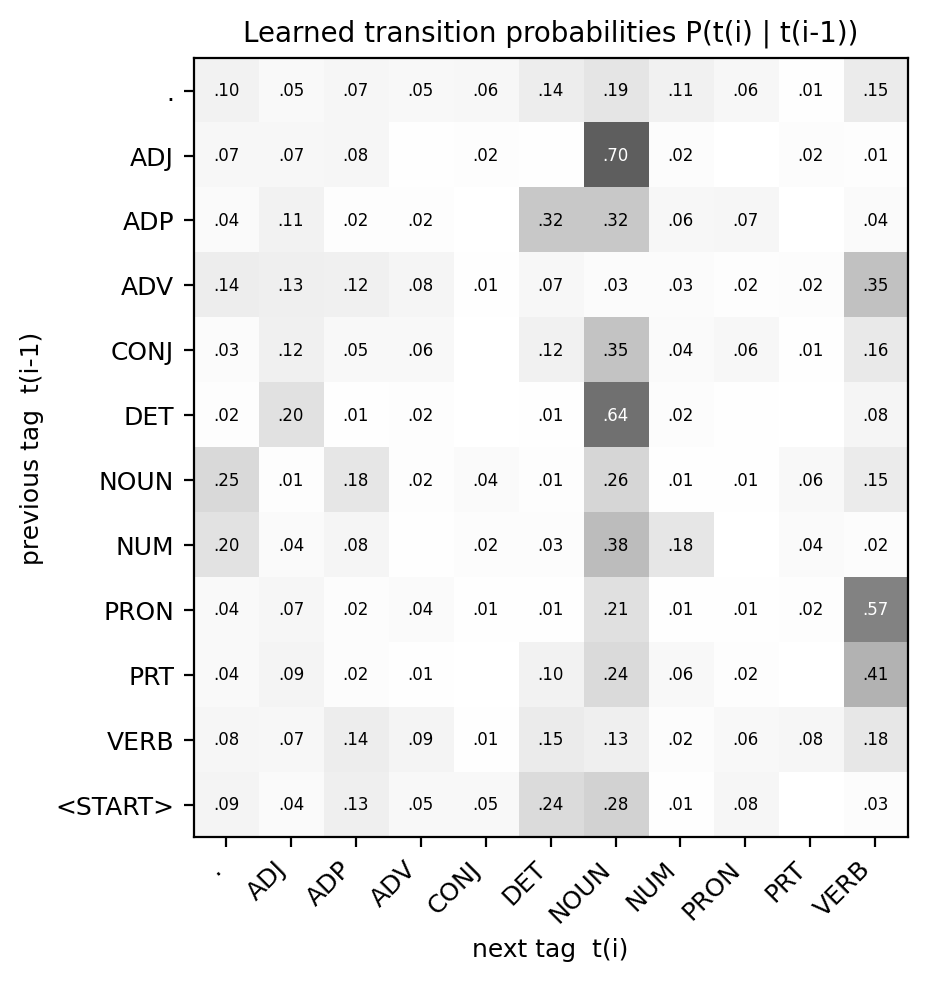

In [5]:
P = np.exp(hmm.log_trans)
fig, ax = plt.subplots(figsize=(6.4, 5.0))
im = ax.imshow(P, cmap="Greys", vmin=0, vmax=1)
for i in range(P.shape[0]):
    for j in range(P.shape[1]):
        ax.text(j, i, f"{P[i, j]:.2f}".lstrip("0") if P[i, j] >= 0.005 else "", ha="center", va="center",
                fontsize=6, color="white" if P[i, j] > 0.5 else "black")
ax.set_xticks(range(len(hmm.tags)), hmm.tags, rotation=45, ha="right")
ax.set_yticks(range(len(hmm.tags) + 1), hmm.tags + ["<START>"])
ax.set_xlabel("next tag  t(i)"); ax.set_ylabel("previous tag  t(i-1)")
ax.set_title("Learned transition probabilities P(t(i) | t(i-1))"); plt.tight_layout(); plt.show()

## b. The same word, different tags – how transitions decide

In [6]:
for s in ["She prepared monthly reports for the finance team .", "She reports to the finance manager every week .",
          "He plans the weekly shifts .", "The plans were approved by the board ."]:
    print(" ".join(f"{w}/{t}" for w, t in hmm.tag(s.split())))
for w in ["reports", "plans", "process"]:
    e = hmm.log_emit[w]
    print(f"P({w!r} | NOUN) = {np.exp(e[hmm.ti['NOUN']]):.2e}   P({w!r} | VERB) = {np.exp(e[hmm.ti['VERB']]):.2e}")
print("P(NOUN | ADJ) =", round(float(P[hmm.ti["ADJ"], hmm.ti["NOUN"]]), 3),
      "  P(VERB | NOUN) =", round(float(P[hmm.ti["NOUN"], hmm.ti["VERB"]]), 3))

She/PRON prepared/VERB monthly/ADJ reports/NOUN for/ADP the/DET finance/NOUN team/NOUN ./.
She/PRON reports/VERB to/PRT the/DET finance/NOUN manager/NOUN every/DET week/NOUN ./.
He/PRON plans/VERB the/DET weekly/ADJ shifts/NOUN ./.
The/DET plans/NOUN were/VERB approved/VERB by/ADP the/DET board/NOUN ./.
P('reports' | NOUN) = 4.25e-04   P('reports' | VERB) = 1.63e-04
P('plans' | NOUN) = 5.02e-04   P('plans' | VERB) = 1.06e-03
P('process' | NOUN) = 5.02e-04   P('process' | VERB) = 8.12e-07
P(NOUN | ADJ) = 0.7   P(VERB | NOUN) = 0.149


## c. Tagging resume sentences
There is no POS-annotated resume corpus, so the HMM output is compared with NLTK's perceptron tagger (agreement, not accuracy).

In [7]:
UNI = {"CONJ": "CONJ", ".": "."}
rows, agree = [], []
lines = {"HR_06": "Benchmarked salaries against market surveys and proposed revised pay bands.",
         "FIN_07": "Prepared the annual budget and rolling forecasts with department heads.",
         "AGR_02": "Monitored greenhouse climate, fertigation and crop scheduling for capsicum and tomato."}
for rid, s in lines.items():
    words = nltk.word_tokenize("I " + s[0].lower() + s[1:])          # bullet fix: tag "I <verb> ...",
    ours = hmm.tag(words)[1:]                                          # then drop the "I"
    ref = nltk.pos_tag(words, tagset="universal")[1:]
    a = np.mean([o[1] == r[1] for o, r in zip(ours, ref)]); agree.append(a)
    print(f"[{rid}] HMM       : " + " ".join(f"{w}/{t}" for w, t in ours))
    print(f"         perceptron: " + " ".join(f"{w}/{t}" for w, t in ref))
    print(f"         agreement {a:.0%}")
print(f"mean agreement on resume sentences: {np.mean(agree):.0%}")

[HR_06] HMM       : benchmarked/VERB salaries/NOUN against/ADP market/NOUN surveys/NOUN and/CONJ proposed/VERB revised/VERB pay/VERB bands/NOUN ./.
         perceptron: benchmarked/VERB salaries/NOUN against/ADP market/NOUN surveys/NOUN and/CONJ proposed/VERB revised/VERB pay/NOUN bands/NOUN ./.
         agreement 91%
[FIN_07] HMM       : prepared/VERB the/DET annual/ADJ budget/NOUN and/CONJ rolling/ADJ forecasts/NOUN with/ADP department/NOUN heads/VERB ./.
         perceptron: prepared/VERB the/DET annual/ADJ budget/NOUN and/CONJ rolling/VERB forecasts/NOUN with/ADP department/NOUN heads/NOUN ./.
         agreement 82%
[AGR_02] HMM       : monitored/VERB greenhouse/ADJ climate/NOUN ,/. fertigation/NOUN and/CONJ crop/NOUN scheduling/VERB for/ADP capsicum/NOUN and/CONJ tomato/NOUN ./.
         perceptron: monitored/VERB greenhouse/NOUN climate/NOUN ,/. fertigation/NOUN and/CONJ crop/NOUN scheduling/NOUN for/ADP capsicum/NOUN and/CONJ tomato/NOUN ./.
         agreement 85%
mean agreement